In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
data = pd.read_csv("cifar-10.csv")

print("Dataset shape:", data.shape)
print(data.head())

Dataset shape: (50000, 3073)
   pixel_0  pixel_1  pixel_2  pixel_3  pixel_4  pixel_5  pixel_6  pixel_7  \
0       59       43       50       68       98      119      139      145   
1      154      126      105      102      125      155      172      180   
2      255      253      253      253      253      253      253      253   
3       28       37       38       42       44       40       40       24   
4      170      168      177      183      181      177      181      184   

   pixel_8  pixel_9  ...  pixel_3063  pixel_3064  pixel_3065  pixel_3066  \
0      149      149  ...          58          65          59          46   
1      142      111  ...          42          67         101         122   
2      253      253  ...          83          80          69          66   
3       32       43  ...          39          59          42          44   
4      189      189  ...          88          85          82          83   

   pixel_3067  pixel_3068  pixel_3069  pixel_3070  

In [3]:
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

print("Features shape:", X.shape)
print("Labels shape:", y.shape)

Features shape: (50000, 3072)
Labels shape: (50000,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (40000, 3072)
Testing data: (10000, 3072)


In [5]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [6]:
model = keras.Sequential([
    layers.Input(shape=(3072,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

In [7]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [8]:
history = model.fit(
    X_train,
    y_train,
    epochs=11,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.3049 - loss: 1.9332 - val_accuracy: 0.3532 - val_loss: 1.8196
Epoch 2/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.3664 - loss: 1.7754 - val_accuracy: 0.3770 - val_loss: 1.7470
Epoch 3/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.3827 - loss: 1.7240 - val_accuracy: 0.3735 - val_loss: 1.7666
Epoch 4/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - accuracy: 0.3963 - loss: 1.6909 - val_accuracy: 0.3835 - val_loss: 1.7132
Epoch 5/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step - accuracy: 0.4062 - loss: 1.6696 - val_accuracy: 0.3995 - val_loss: 1.6906
Epoch 6/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 17s 7ms/step - accuracy: 0.4178 - loss: 1.6437 - val_accuracy: 0.4270 - val_loss: 1.6467
Epoch 7/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.4196 - loss: 1.6291 - val_accuracy: 0.4070 - val_loss: 1.6718
Epoch 8/11
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.4245 - loss: 

In [9]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4257 - loss: 1.6314
Test Loss: 1.6313633918762207
Test Accuracy: 42.570000886917114 %


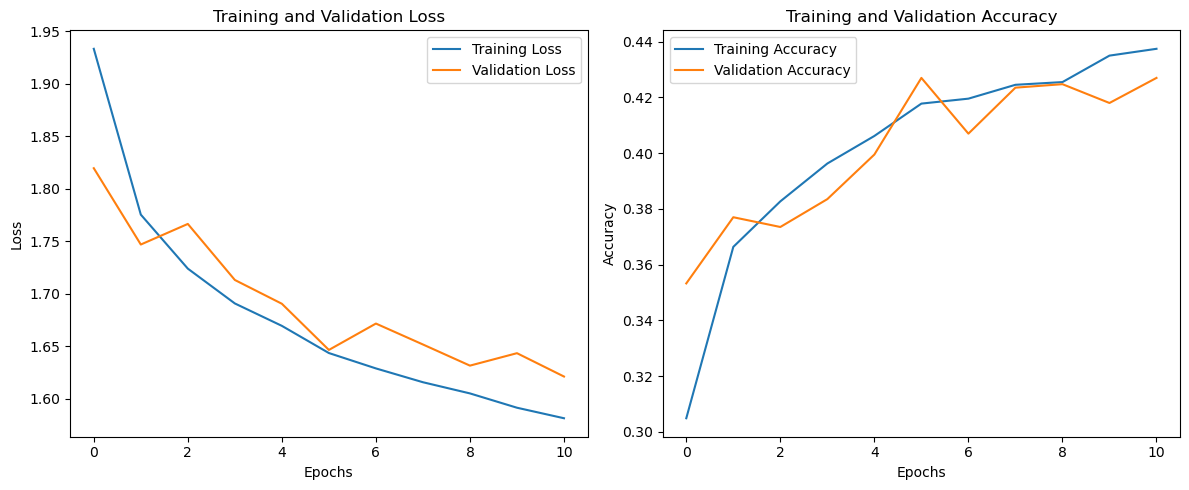

In [10]:
plt.figure(figsize=(12, 5))

# Training and validation loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()